# Analyzing the Results from GFN and Small Diamonds Code

The results from all runs are aggregated into a database using the file 
`gflow-phys/aggregate_plotting/data_aggregate_to_sql.py`. To add more data to the database from new runs, run `python gflow-phys/aggregate_plotting/data_aggregate_to_sql.py` and edit the python file with the location of new output data runs as needed. 


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import json
import io
import sys
from pathlib import Path

ROOT = Path("/Users/alexastewart/research/gflow-phys"); SQL_DATABASE = ROOT / "aggregate_plotting/sergio_results.sqlite"; plt.style.use("ggplot")
with sqlite3.connect(SQL_DATABASE.resolve().as_uri() + "?mode=ro", uri=True) as conn:
    docs = conn.execute("SELECT path,content FROM archived_files WHERE path LIKE '%ising_chi_sweep.json'").fetchall(); labels = dict(conn.execute("SELECT source_path,neural_variant FROM run_labels"))
rows = [{"source_path": p, "variant": labels.get(p, "tilt" if "/outputs/local_iter3000_tilted" in p else "baseline"), "iterations": 3000 if "/outputs/local_iter3000" in p else 1500, "seed": int(Path(p).parent.name.removeprefix("seed_")), "method": m, "T": T, "chi": v} for p,b in docs if "/outputs/ising_5x5_refactored/" in p or "/outputs/local_iter3000" in p for d in [json.loads(b)] for m in ["tb","kc"] if f"chi_{m}_mean" in d for T,v in zip(d["T_grid"],d[f"chi_{m}_mean"])]
df = pd.DataFrame(rows); assert not df.empty, "No matching results"; assert not df.duplicated(["iterations","seed","method","T","variant"]).any(), "Repeated runs within a variant: inspect source_path"
stats = df.groupby(["iterations","method","variant","T"])["chi"].agg(["mean","sem"]).reset_index()

# Training Budget Comparison

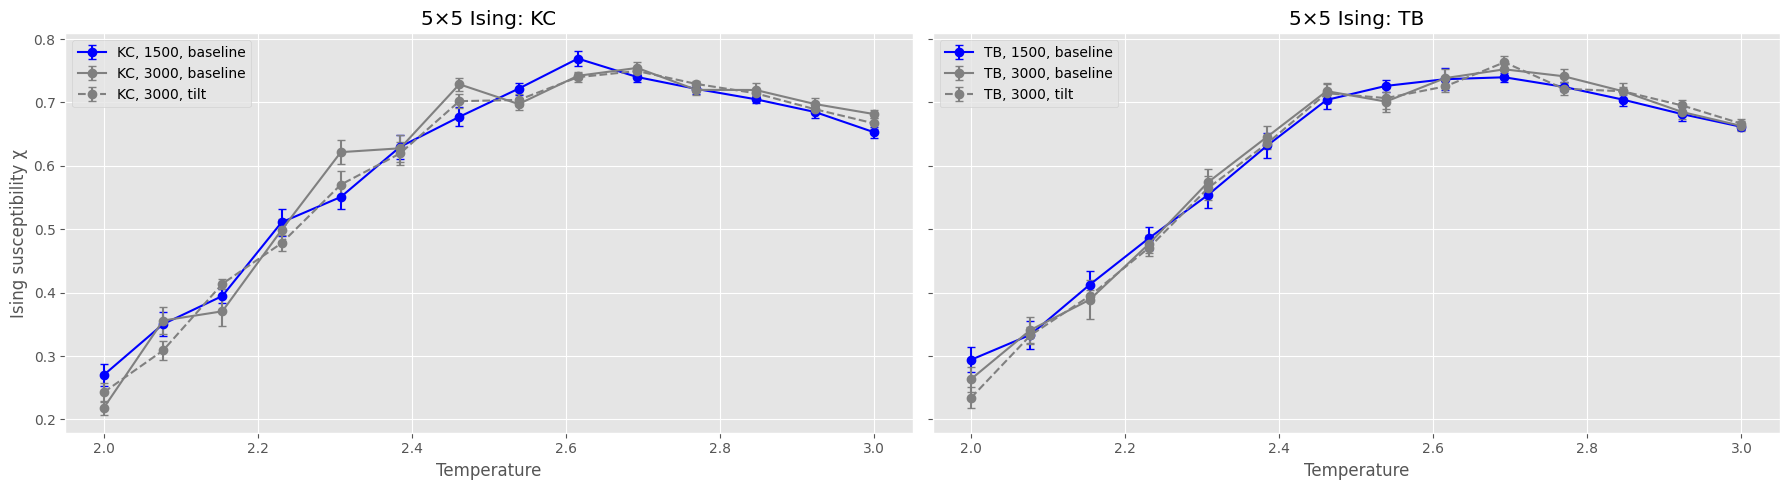

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
colors = {1500: "blue", 3000: "grey"}
for ax, name in zip(axes, ["kc", "tb"]):
    for (iterations, method, variant), g in stats.groupby(["iterations", "method", "variant"]):
        if method.lower() == name:
            ax.errorbar(g["T"], g["mean"], yerr=g["sem"].fillna(0), color=colors[iterations], linestyle="--" if variant == "tilt" else "-", marker="o", capsize=3, label=f"{method.upper()}, {iterations}, {variant}")
    ax.set(xlabel="Temperature", title=f"5×5 Ising: {name.upper()}"); ax.legend()
axes[0].set_ylabel("Ising susceptibility χ"); fig.tight_layout(); plt.show()

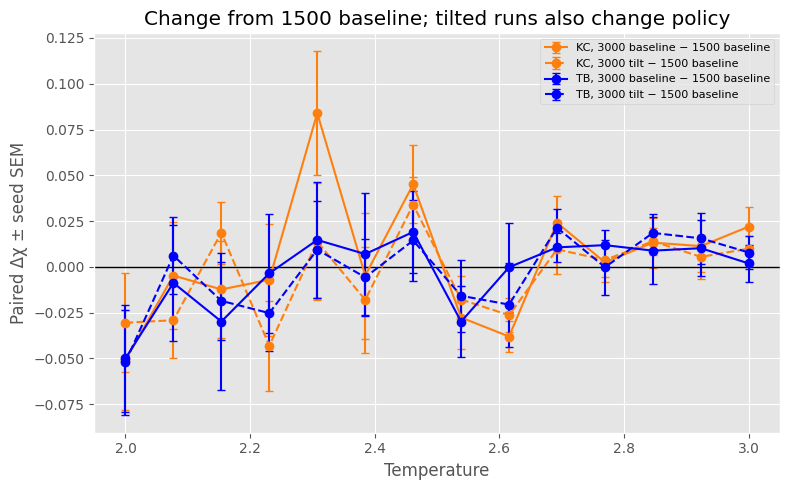

In [16]:

method_colors = {"tb": "blue", "kc": "tab:orange"}
base = df[(df.iterations == 1500) & (df.variant == "baseline")][["seed", "method", "T", "chi"]].rename(columns={"chi": "baseline_chi"})
p = df[df.iterations == 3000].merge(base, on=["seed", "method", "T"], validate="many_to_one"); p["change"] = p.chi - p.baseline_chi
s = p.groupby(["method", "variant", "T"]).change.agg(["mean", "sem"]).reset_index()
fig, ax = plt.subplots(figsize=(8, 5))
for (method, variant), g in s.groupby(["method", "variant"]):
    ax.errorbar(g["T"], g["mean"], yerr=g["sem"].fillna(0), color=method_colors[method], linestyle="--" if variant == "tilt" else "-", marker="o", capsize=3, label=f"{method.upper()}, 3000 {variant} − 1500 baseline")
ax.axhline(0, color="black", lw=1); ax.set(xlabel="Temperature", ylabel="Paired Δχ ± seed SEM", title="Change from 1500 baseline; tilted runs also change policy"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()


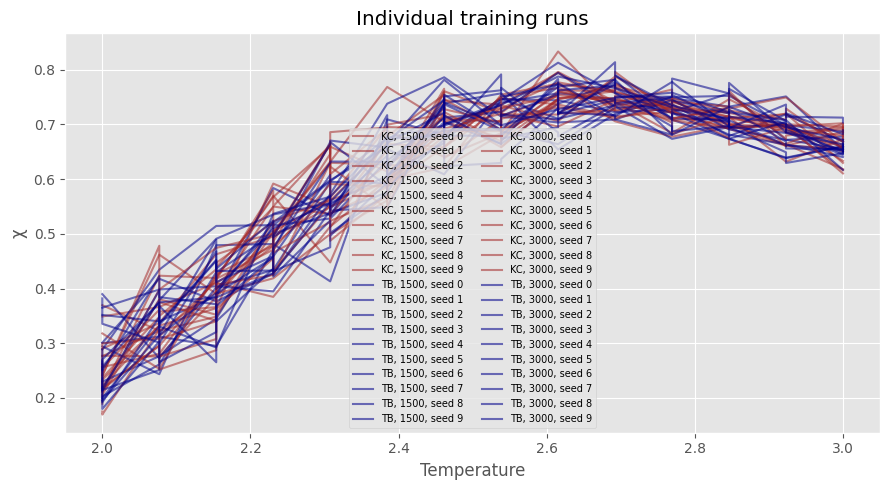

In [17]:
# Seed Curves

fig, ax = plt.subplots(figsize=(9, 5))
colors={"kc":"brown","tb":"darkblue"}
for (budget, method, seed), g in df.groupby(["iterations", "method", "seed"]):
    g = g.sort_values("T")
    ax.plot(g["T"], g.chi, alpha=.55, color=colors[method],label=f"{method.upper()}, {budget}, seed {seed}")
ax.set(xlabel="Temperature", ylabel="χ", title="Individual training runs")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

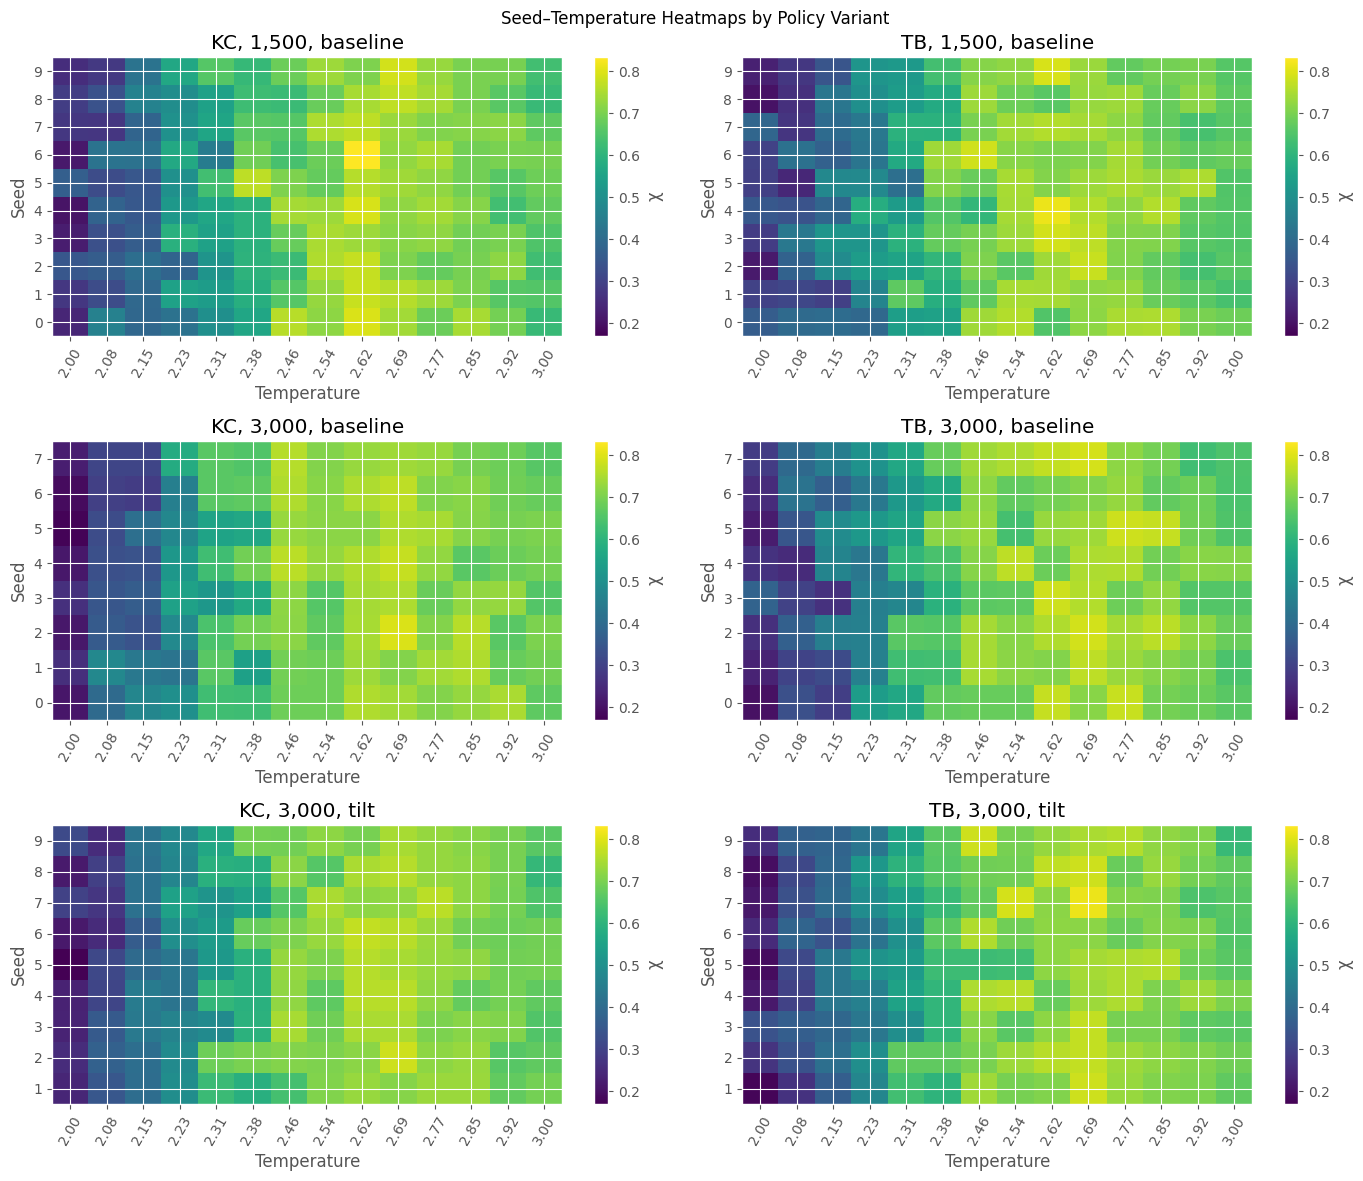

In [18]:
# Seed–temperature heatmaps at 1,500 iterations

# d = df[df.iterations.isin([1500, 3000])]; methods = sorted(d.method.unique())
# fig, axes = plt.subplots(2, 2, figsize=(14, 8))
# for ax, (n, method) in zip(axes.flat, ((n, m) for n in [1500, 3000] for m in methods)):
#     p = d[(d.iterations == n) & (d.method == method)].pivot(index="seed", columns="T", values="chi").sort_index(axis=1)
#     im = ax.imshow(p, aspect="auto", origin="lower", vmin=d.chi.min(), vmax=d.chi.max())
#     ax.set(title=f"{method.upper()}, {n:,} iterations", xlabel="Temperature", ylabel="Seed"); ax.set_xticks(range(len(p.columns)), [f"{t:.2f}" for t in p.columns], rotation=60); ax.set_yticks(range(len(p.index)), p.index); fig.colorbar(im, ax=ax, label="χ")
# fig.suptitle("Seed Temperature Heatmap")
# plt.tight_layout()
# plt.show()

d = df[df.iterations.isin([1500, 3000])]; methods = sorted(d.method.unique()); conditions = sorted(set(zip(d.iterations, d.variant)))
fig, axes = plt.subplots(len(conditions), len(methods), figsize=(7*len(methods), 4*len(conditions)), squeeze=False)
for i, (n, variant) in enumerate(conditions):
    for j, method in enumerate(methods):
        ax = axes[i, j]; sub = d[(d.iterations == n) & (d.variant == variant) & (d.method == method)]
        if sub.empty: ax.set_visible(False); continue
        p = sub.pivot(index="seed", columns="T", values="chi").sort_index(axis=1); im = ax.imshow(p, aspect="auto", origin="lower", vmin=d.chi.min(), vmax=d.chi.max())
        ax.set(title=f"{method.upper()}, {n:,}, {variant}", xlabel="Temperature", ylabel="Seed"); ax.set_xticks(range(len(p.columns)), [f"{t:.2f}" for t in p.columns], rotation=60); ax.set_yticks(range(len(p.index)), p.index); fig.colorbar(im, ax=ax, label="χ")
fig.suptitle("Seed–Temperature Heatmaps by Policy Variant"); fig.tight_layout(); plt.show()

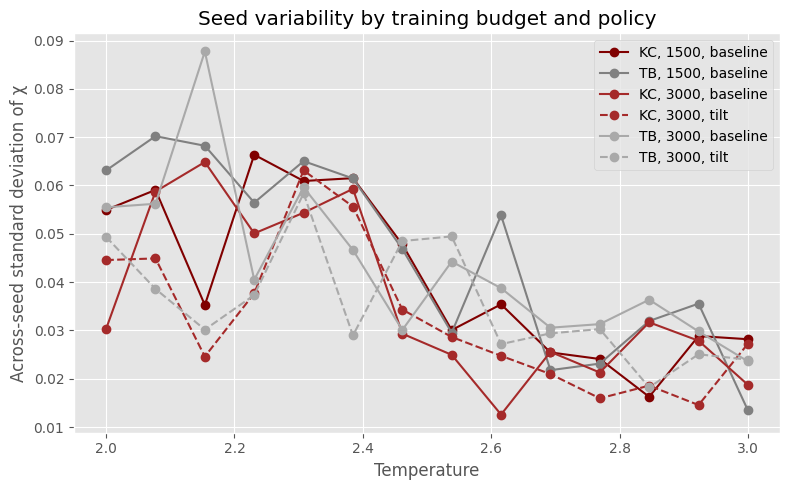

In [19]:
# # Seed variability versus temperature
# s = df.groupby(["iterations", "method", "T"]).chi.std().reset_index(name="std")
# fig, ax = plt.subplots(figsize=(8, 5))

# colors={"tb":{3000:"darkgrey", 1500:"grey"}, "kc":{3000:"brown",1500:"maroon"}}

# for (iters, method), g in s.groupby(["iterations", "method"]):
#     ax.plot(g["T"], g["std"], marker="o", color=colors[method][iters], label=f"{method.upper()}, {iters}")
    
# ax.set(xlabel="Temperature", ylabel="Across-seed standard deviation of χ", title="Higher Variance Runs for Low T")
# ax.legend(); plt.tight_layout(); plt.show()

s = df.groupby(["iterations", "method", "variant", "T"]).chi.agg(["std", "count"]).reset_index()
s = s[s["count"] >= 2]
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"tb": {3000: "darkgrey", 1500: "grey"}, "kc": {3000: "brown", 1500: "maroon"}}
for (iters, method, variant), g in s.groupby(["iterations", "method", "variant"]):
    ax.plot(g["T"], g["std"], marker="o", color=colors[method][iters], linestyle="--" if variant == "tilt" else "-", label=f"{method.upper()}, {iters}, {variant}")
ax.set(xlabel="Temperature", ylabel="Across-seed standard deviation of χ", title="Seed variability by training budget and policy")
ax.legend(); plt.tight_layout(); plt.show()

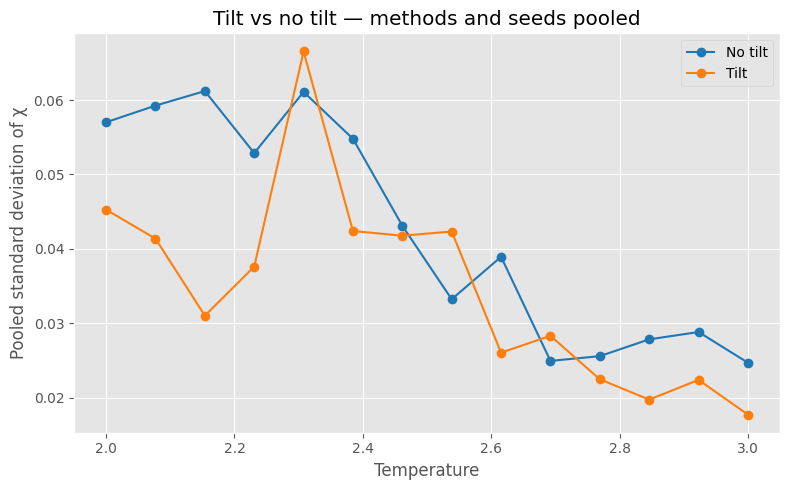

In [56]:
s = df.groupby(["variant", "T"]).chi.agg(["std", "count"]).reset_index()
s = s[s["count"] >= 2]
fig, ax = plt.subplots(figsize=(8, 5))
for variant, color in [("baseline", "tab:blue"), ("tilt", "tab:orange")]:
    g = s[s.variant == variant].sort_values("T")
    ax.plot(g["T"], g["std"], marker="o", color=color, label="No tilt" if variant == "baseline" else "Tilt")
ax.set(xlabel="Temperature", ylabel="Pooled standard deviation of χ", title="Tilt vs no tilt — methods and seeds pooled")
ax.legend(); plt.tight_layout(); plt.show()



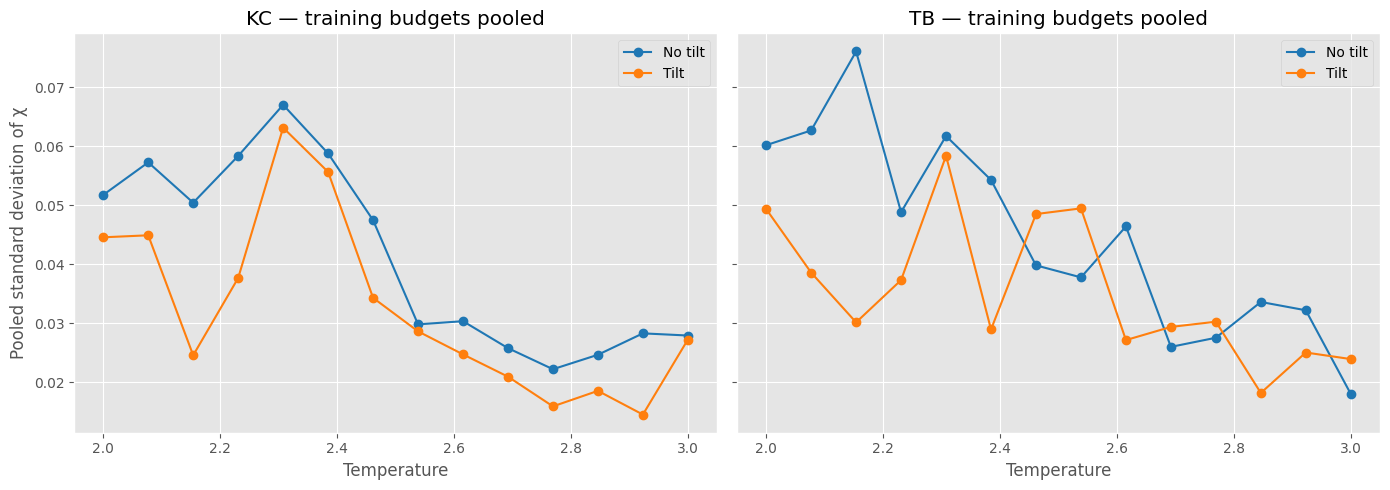

In [20]:
s = df.groupby(["method", "variant", "T"]).chi.agg(["std", "count"]).reset_index()
s = s[s["count"] >= 2]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, method in zip(axes, ["kc", "tb"]):
    for variant, color in [("baseline", "tab:blue"), ("tilt", "tab:orange")]:
        g = s[(s.method == method) & (s.variant == variant)].sort_values("T")
        ax.plot(g["T"], g["std"], marker="o", color=color, label="No tilt" if variant == "baseline" else "Tilt")
    ax.set(xlabel="Temperature", title=f"{method.upper()} — training budgets pooled"); ax.legend()
axes[0].set_ylabel("Pooled standard deviation of χ"); fig.tight_layout(); plt.show()

                                                                                                                   source_path  iterations  seed method
         /Users/alexastewart/research/gflow-phys/GFN_Thesis/outputs/local_iter3000_20261111_145139/seed_1/ising_chi_sweep.json        3000     1     tb
         /Users/alexastewart/research/gflow-phys/GFN_Thesis/outputs/local_iter3000_20261111_145139/seed_1/ising_chi_sweep.json        3000     1     kc
         /Users/alexastewart/research/gflow-phys/GFN_Thesis/outputs/local_iter3000_20261111_145139/seed_0/ising_chi_sweep.json        3000     0     tb
         /Users/alexastewart/research/gflow-phys/GFN_Thesis/outputs/local_iter3000_20261111_145139/seed_0/ising_chi_sweep.json        3000     0     kc
/Users/alexastewart/research/gflow-phys/GFN_Thesis/outputs/local_iter3000_followup_20261111_154207/seed_2/ising_chi_sweep.json        3000     2     tb
/Users/alexastewart/research/gflow-phys/GFN_Thesis/outputs/local_iter3000_followup_20261

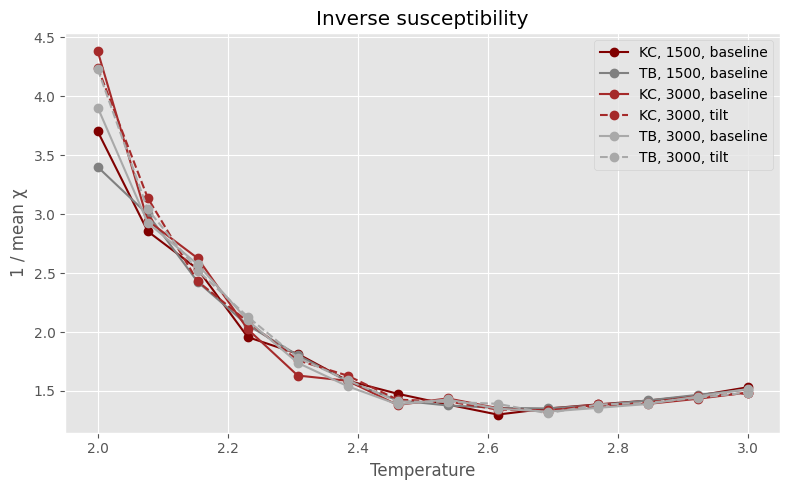

In [21]:
import sqlite3, json
with sqlite3.connect(SQL_DATABASE) as conn: docs = conn.execute("SELECT path,content FROM archived_files WHERE path LIKE '%ising_chi_sweep.json'").fetchall()
rows = [{"source_path": p, "iterations": 3000 if "/outputs/local_iter3000" in p else 1500, "seed": int(Path(p).parent.name.removeprefix("seed_")), "method": m, "T": T, "chi": v} for p,b in docs if "/outputs/ising_5x5_refactored/" in p or "/outputs/local_iter3000" in p for d in [json.loads(b)] for m in ["tb","kc"] if f"chi_{m}_mean" in d for T,v in zip(d["T_grid"],d[f"chi_{m}_mean"])]
df = pd.DataFrame(rows)
assert not df.empty, "No matching sweep results"
print(df[["source_path", "iterations", "seed", "method"]].drop_duplicates().to_string(index=False))
with sqlite3.connect(SQL_DATABASE) as conn: labels = dict(conn.execute("SELECT source_path,neural_variant FROM run_labels"))
df["variant"] = df["source_path"].map(labels).fillna("baseline"); assert not df.duplicated(["iterations","method","T","seed","variant"]).any(), "Repeated runs within a variant"
s = df.groupby(["iterations","method","variant","T"]).chi.mean().reset_index(); s = s[s.chi > 1e-12]
fig, ax = plt.subplots(figsize=(8, 5))
for (budget, method, variant), g in s.groupby(["iterations","method","variant"]):
    ax.plot(g["T"], 1/g.chi, marker="o", color=colors[method][budget], linestyle="--" if variant=="tilt" else "-", label=f"{method.upper()}, {budget}, {variant}")
ax.set(xlabel="Temperature", ylabel="1 / mean χ", title="Inverse susceptibility"); ax.legend(); plt.tight_layout(); plt.show()

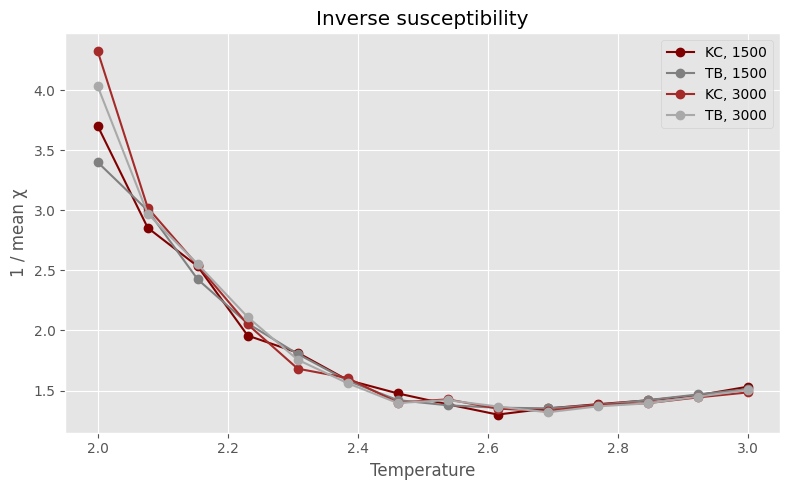

In [22]:
# inverse susceptibility

import matplotlib.pyplot as plt
s = df.groupby(["iterations", "method", "T"]).chi.mean().reset_index()
s = s[s.chi > 1e-12]
fig, ax = plt.subplots(figsize=(8, 5))
for (budget, method), g in s.groupby(["iterations", "method"]):
    ax.plot(g["T"], 1 / g.chi, marker="o",color=colors[method][budget], label=f"{method.upper()}, {budget}")
ax.set(xlabel="Temperature", ylabel="1 / mean χ", title="Inverse susceptibility")
ax.legend(); plt.tight_layout(); plt.show()

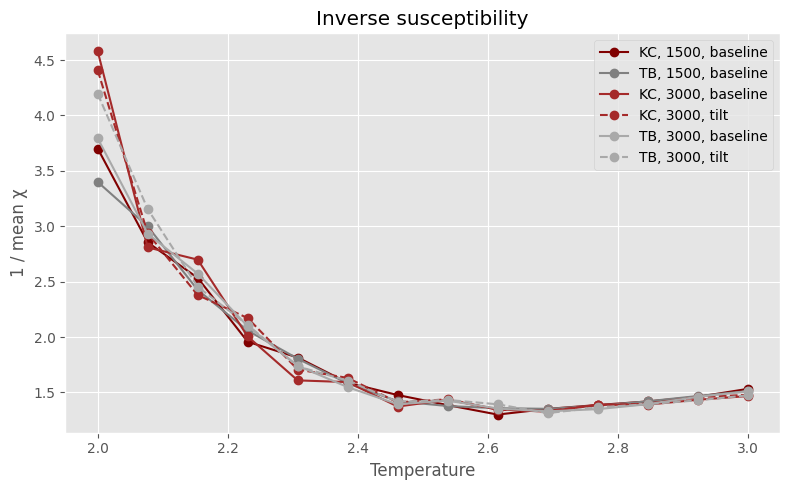

In [36]:
import sqlite3
with sqlite3.connect(SQL_DATABASE) as conn: labels = dict(conn.execute("SELECT source_path,neural_variant FROM run_labels"))
df["variant"] = df["source_path"].map(labels).fillna("baseline"); assert not df.duplicated(["iterations","method","T","seed","variant"]).any(), "Repeated runs within a variant"
s = df.groupby(["iterations","method","variant","T"]).chi.mean().reset_index(); s = s[s.chi > 1e-12]
fig, ax = plt.subplots(figsize=(8, 5))
for (budget, method, variant), g in s.groupby(["iterations","method","variant"]):
    ax.plot(g["T"], 1/g.chi, marker="o", color=colors[method][budget], linestyle="--" if variant=="tilt" else "-", label=f"{method.upper()}, {budget}, {variant}")
ax.set(xlabel="Temperature", ylabel="1 / mean χ", title="Inverse susceptibility"); ax.legend(); plt.tight_layout(); plt.show()

In [23]:
# Method Disagrement

p = df.pivot(index=["iterations", "seed", "T"], columns="method", values="chi").dropna(subset=["tb", "kc"]).reset_index()
p = p[p.kc.abs() > 1e-12].copy()
p["relative"] = 100 * (p.tb - p.kc) / p.kc
fig, ax = plt.subplots(figsize=(8, 5))
for budget, g in p.groupby("iterations"):
    s = g.groupby("T").relative.agg(["mean", "sem"])
    ax.errorbar(s.index, s["mean"], yerr=s["sem"].fillna(0), marker="o", capsize=3, label=f"{budget} iterations")
ax.axhline(0, color="black", lw=1)
ax.set(xlabel="Temperature", ylabel="100 × [χ(TB) − χ(KC)] / χ(KC)", title="Relative method disagreement")
ax.legend(); plt.tight_layout(); plt.show()

ValueError: Index contains duplicate entries, cannot reshape

# Sanity Check: Visualize an individual sample

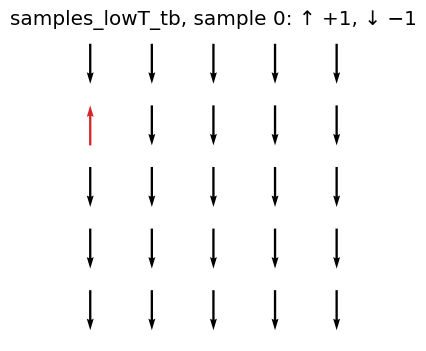

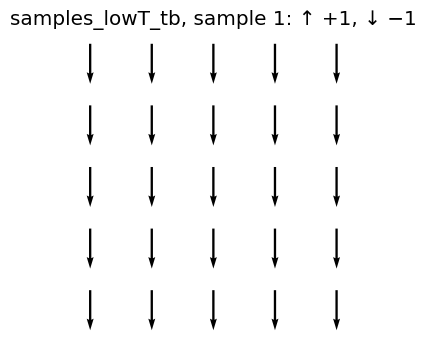

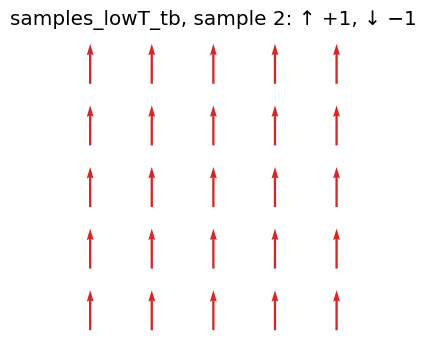

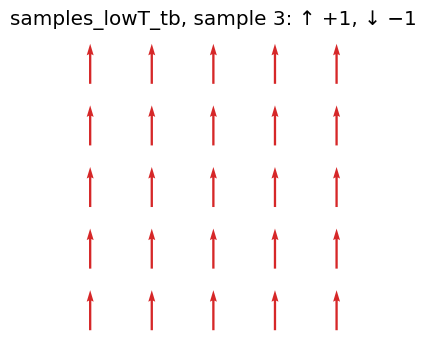

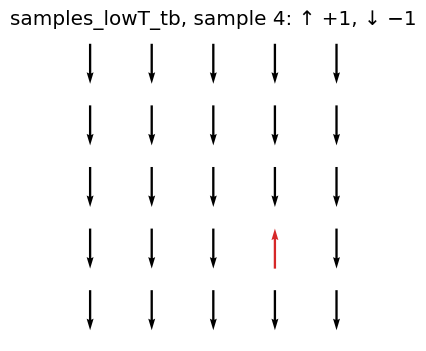

In [37]:
import re

GRID = True
KEY = "samples_lowT_tb"
for SAMPLE in range(5):
    conn = sqlite3.connect(SQL_DATABASE.resolve().as_uri() + "?mode=ro", uri=True)
    
    entry = pd.read_sql_query("SELECT * FROM npz_catalog WHERE array_key=? AND source_path LIKE '%/ising_5x5_refactored/seed_0/%' LIMIT 1", conn, params=[KEY]).iloc[0]
    table = entry.table_name; assert re.fullmatch(r"npz_[0-9a-f]{16}_\d+", table); row = pd.read_sql_query(f'SELECT * FROM "{table}" WHERE source_path=? AND array_key=? AND row_index=?', conn, params=[entry.source_path, KEY, SAMPLE])
    spins = row[sorted([c for c in row if c.startswith("value_")], key=lambda c: int(c.split("_")[1]))].to_numpy().ravel(); ncols = int(np.sqrt(len(spins))) if GRID else len(spins); assert len(spins) % ncols == 0; y, x = np.indices((len(spins)//ncols, ncols)); s = spins.reshape(y.shape)
    fig, ax = plt.subplots(figsize=(4, 4) if GRID else (14, 2)) 
    
    ax.quiver(x, -y, np.zeros_like(s), .65*s, color=np.where(s.ravel()>0, "tab:red", "black"), angles="xy", scale_units="xy", scale=1, pivot="middle")
    
    ax.set(xlim=(-.5,ncols-.5), ylim=(-y.shape[0]+.5,.5), title=f"{KEY}, sample {SAMPLE}: ↑ +1, ↓ −1"); ax.set_aspect("equal"); ax.set_axis_off(); plt.show(); conn.close()

# Compare to Bolzmann Distribution Sampling


## Histogram: Number of Up and Down Spins vs Number of configurations. 

The histogram tells you for Ising, EA, and SK, out of the trajectories produced by the GFlowNet, how many were up/down. 

Ising: /Users/alexastewart/research/gflow-phys/GFN_Thesis/outputs/ising_5x5_refactored/seed_0/ising_raw_data.npz
  800 samples, D=25, T=2.0
  Enumerating D=25: 0/33,554,432
  Enumerating D=25: 8,388,608/33,554,432
  Enumerating D=25: 16,777,216/33,554,432
  Enumerating D=25: 25,165,824/33,554,432


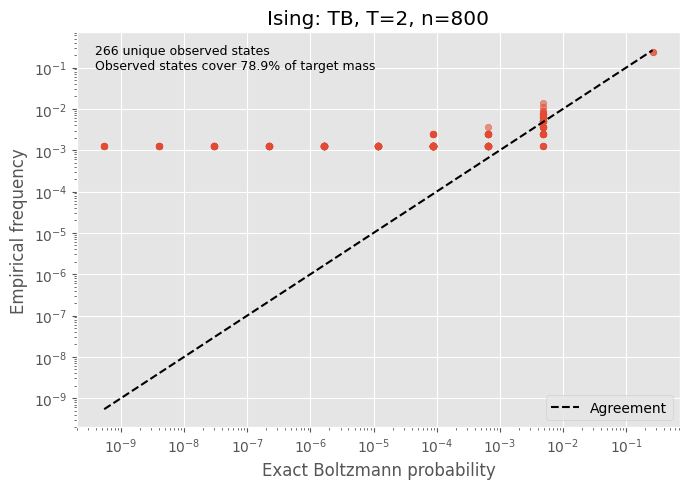

In [24]:
sys.path.insert(0, str(ROOT / "GFN_Thesis"))
from spin_glass_lib import SpinEnv

METHOD, ENDPOINT = "tb", "lowT"  # Also try kc/mcmc and highT.
SOURCE_FRAGMENTS = {
    "Ising": "/outputs/ising_5x5_refactored/seed_0/",
    # "EA": "/outputs/smoke_test_refactor_ea/",
    # "SK": "/outputs/smoke_test_refactor_sk/",
}
# Replace None with VERIFIED settings; e.g. 0.5 and 0 only if those were used.
DISORDER = {
    "EA": {"p_af": None, "J_seed": None},
    "SK": {"p_af": None, "J_seed": None},
}
MAX_EXACT_D = 25
samples_by_model = {}

def energies(X, env):
    E = np.zeros(len(X), dtype=np.float64)
    for (i, j), coupling in env.J.items():
        E -= coupling * X[:, i] * X[:, j]
    return E

def exact_logZ(env, T, chunk=32768):
    """Enumerate all terminal configurations, without pairwise overlap matrices."""
    D = env.D
    if D > MAX_EXACT_D:
        raise ValueError(f"D={D} exceeds exact-enumeration limit {MAX_EXACT_D}")
    total, logZ = 1 << D, -np.inf
    bits = np.arange(D, dtype=np.uint64)
    for start in range(0, total, chunk):
        codes = np.arange(start, min(start + chunk, total), dtype=np.uint64)
        X = (((codes[:, None] >> bits) & 1).astype(np.int8) * 2 - 1)
        logZ = np.logaddexp(logZ, np.logaddexp.reduce(-energies(X, env) / T))
        if start % max(chunk, total // 4) == 0:
            print(f"  Enumerating D={D}: {start:,}/{total:,}", flush=True)
    return float(logZ)

fig, ax = plt.subplots(figsize=(7, 5))
axes = [ax]

# fig, axes = plt.subplots(1, 3, figsize=(17, 5))
conn = sqlite3.connect(SQL_DATABASE.resolve().as_uri() + "?mode=ro", uri=True)

try:
    paths = [r[0] for r in conn.execute(
        "SELECT path FROM archived_files WHERE extension='.npz' ORDER BY path")]
    for ax, (model, fragment) in zip(axes, SOURCE_FRAGMENTS.items()):
        if model !="Ising":
            pass
        ax.set(title=model, xlabel="Exact Boltzmann probability",
               ylabel="Empirical frequency")
        matches = [p for p in paths if fragment in p]
        if not matches:
            ax.text(.5, .5, "No matching NPZ", ha="center", transform=ax.transAxes)
            continue
        source = matches[0]
        blob = conn.execute(
            "SELECT content FROM archived_files WHERE path=?", (source,)
        ).fetchone()[0]
        key = f"samples_{ENDPOINT}_{METHOD}"
        with np.load(io.BytesIO(blob), allow_pickle=False) as archive:
            if key not in archive.files or key + "_T" not in archive.files:
                ax.text(.5, .5, f"Missing {key}", ha="center", transform=ax.transAxes)
                continue
            X = archive[key].copy()
            T = float(np.asarray(archive[key + "_T"]).item())
        samples_by_model[model] = {"X": X, "T": T, "source": source}
        print(f"{model}: {source}\n  {len(X)} samples, D={X.shape[1]}, T={T}")

        D = X.shape[1]
        if model != "Ising" and any(v is None for v in DISORDER[model].values()):
            ax.text(.5, .5, "Set verified p_af and J_seed",
                    ha="center", transform=ax.transAxes)
            continue
        if D > MAX_EXACT_D:
            ax.text(.5, .5, f"D={D}: too large for enumeration",
                    ha="center", transform=ax.transAxes)
            continue
        if model in ("Ising", "EA"):
            N = int(np.sqrt(D))
            if N * N != D or N < 3:
                raise ValueError("Grid energy requires square lattice with N >= 3")
            kwargs = {} if model == "Ising" else DISORDER[model]
            env = SpinEnv(model.lower(), N=N, **kwargs)
        else:
            env = SpinEnv("sk", D=D, **DISORDER[model])

        logZ = exact_logZ(env, T)
        states, counts = np.unique(X, axis=0, return_counts=True)
        empirical = counts / len(X)
        exact = np.exp(-energies(states, env) / T - logZ)
        ax.scatter(exact, empirical, alpha=.55, s=22)
        lo, hi = min(exact.min(), empirical.min()), max(exact.max(), empirical.max())
        ax.plot([lo, hi], [lo, hi], "k--", label="Agreement")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"{model}: {METHOD.upper()}, T={T:g}, n={len(X)}")
        ax.text(.03, .97, f"{len(states)} unique observed states\n"
                f"Observed states cover {exact.sum():.1%} of target mass",
                transform=ax.transAxes, va="top", fontsize=9)
        ax.legend()
finally:
    conn.close()
plt.tight_layout()
plt.show()

In [139]:
def exact_boltzmann_counts(model, X, T):
    """
    Calculates given the model, X, and T what the expected number of up spins will be for a configuration assuming Boltzmann distribution sampling. 
    """
    D = X.shape[1]; assert D <= 25, "Too large for enumeration"
    settings = {} 
    if model == "Ising":
        assert all(v is not None for v in settings.values()), "Fill verified DISORDER settings"
    else:
        DISORDER[model]
    env = SpinEnv(model.lower(), **({"D": D} if model == "SK" else {"N": int(np.sqrt(D))}), **settings); mass = np.zeros(D+1); shift = sum(abs(j) for j in env.J.values())
    for start in range(0, 1 << D, 32768):
        codes = np.arange(start, min(start+32768, 1 << D), dtype=np.uint64); states = (((codes[:, None] >> np.arange(D, dtype=np.uint64)) & 1).astype(np.int8)*2-1); mass += np.bincount((states > 0).sum(axis=1), weights=np.exp(-(energies(states, env)+shift)/T), minlength=D+1)
    return len(X)*mass/mass.sum()

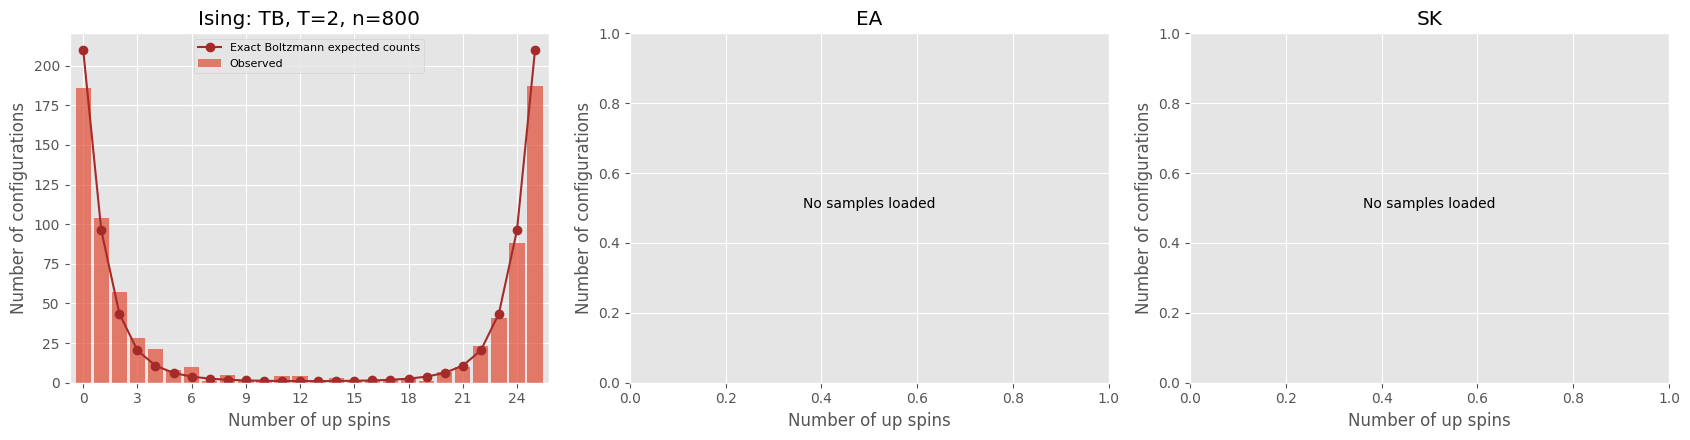

<Figure size 640x480 with 0 Axes>

In [151]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for METHOD in ["tb","kc"]:
    for ax, model in zip(axes, ["Ising", "EA", "SK"]):
        ax.set(title=model, xlabel="Number of up spins", ylabel="Number of configurations")
        if model not in samples_by_model:
            ax.text(.5, .5, "No samples loaded", ha="center", transform=ax.transAxes)
            continue
        record = samples_by_model[model]
        X, T = record["X"], record["T"]
        D = X.shape[1]
        up = (X > 0).sum(axis=1)
        counts = np.bincount(up, minlength=D + 1)
    
        # Observed counts 
        ax.bar(np.arange(D + 1), counts, width=.85, alpha=.7, label="Observed")
    
        # Expected counts assuming boltzmann
        ax.plot(np.arange(D+1), exact_boltzmann_counts(model, X, T), "-o", color="brown", label="Exact Boltzmann expected counts")
        
        #ax.plot(np.arange(D + 1), counts[::-1], "k--",  label="Observed histogram reflected")
        #ax.axvline(D / 2, color="gray", ls=":", label="Half up")
        ax.set_title(f"{model}: {METHOD.upper()}, T={T:g}, n={len(X)}")
        ax.set_xlim(-.75, D + .75)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.legend(fontsize=8)
        
    plt.tight_layout()
    plt.show()

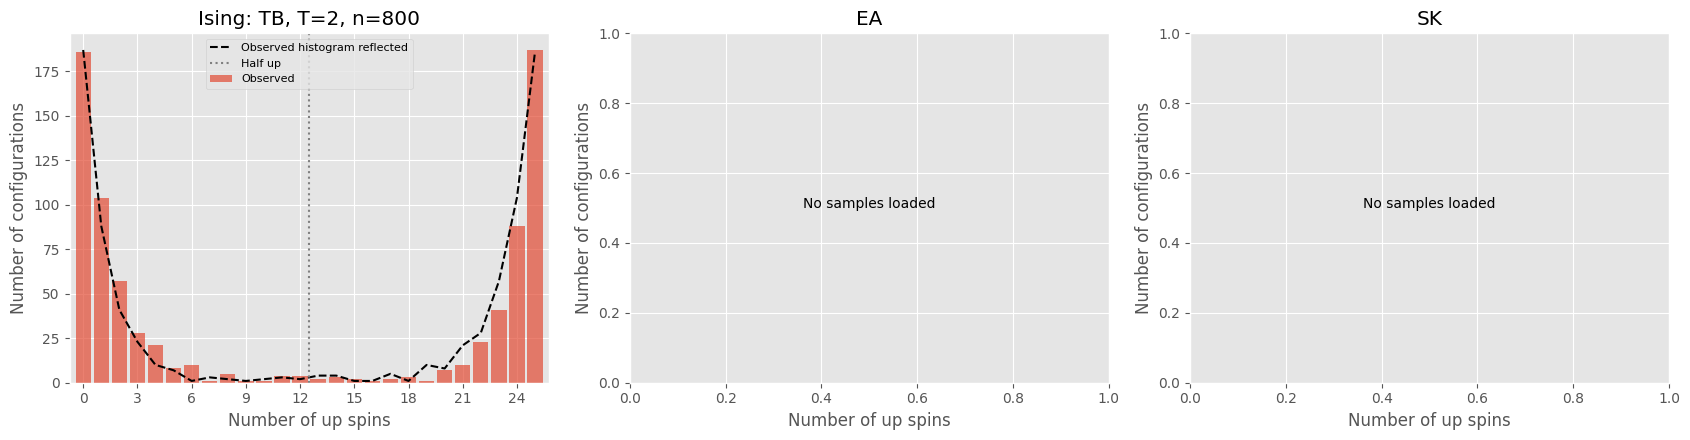

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

METHOD, ENDPOINT = "tb", "highT"  # Also try kc/mcmc and highT.
for ax, model in zip(axes, ["Ising", "EA", "SK"]):
    ax.set(title=model, xlabel="Number of up spins", ylabel="Number of configurations")
    if model not in samples_by_model:
        ax.text(.5, .5, "No samples loaded", ha="center", transform=ax.transAxes)
        continue
    record = samples_by_model[model]
    X, T = record["X"], record["T"]
    D = X.shape[1]
    up = (X > 0).sum(axis=1)
    counts = np.bincount(up, minlength=D + 1)
    ax.bar(np.arange(D + 1), counts, width=.85, alpha=.7, label="Observed")
    ax.plot(np.arange(D + 1), counts[::-1], "k--",
            label="Observed histogram reflected")
    
    ax.axvline(D / 2, color="gray", ls=":", label="Half up")
    
    ax.set_title(f"{model}: {METHOD.upper()}, T={T:g}, n={len(X)}")
    ax.set_xlim(-.75, D + .75)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.legend(fontsize=8)
    
plt.tight_layout()
plt.show()

In [2]:
import sqlite3
db = sqlite3.connect("/Users/alexastewart/research/gflow-phys/aggregate_plotting/sergio_results.sqlite")
db.execute("CREATE TABLE IF NOT EXISTS run_labels(source_path TEXT PRIMARY KEY, neural_variant TEXT, tilt_strength REAL)")
paths = [p for p, in db.execute("SELECT path FROM archived_files") if "/GFN_Thesis/outputs/local_iter3000_tilted" in p]; assert paths, "Import the tilted outputs first"
db.executemany("INSERT OR REPLACE INTO run_labels VALUES(?,?,?)", [(p, "tilt", None) for p in paths])  # Replace None with verified strength.
db.commit(); print(f"Labeled {len(paths)} files as tilted"); db.close()

Labeled 21 files as tilted


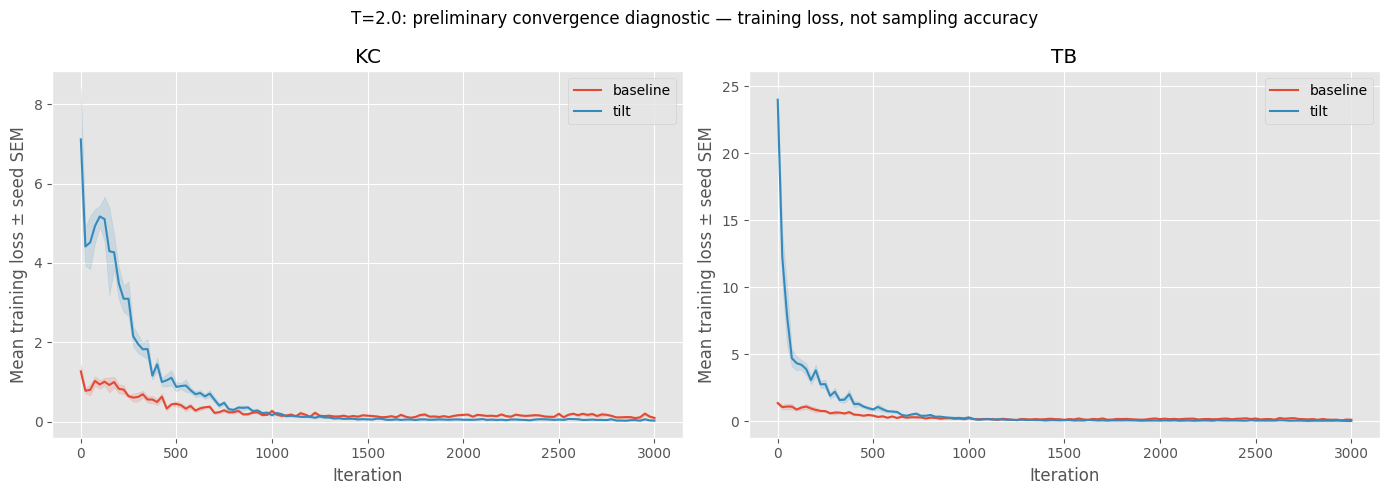

In [58]:
import io, sqlite3, matplotlib.pyplot as plt
with sqlite3.connect(SQL_DATABASE) as conn: files = conn.execute("SELECT path,content FROM archived_files WHERE extension='.npz' AND path LIKE '%/outputs/local_iter3000%'").fetchall(); labels = dict(conn.execute("SELECT source_path,neural_variant FROM run_labels"))
records = []
for path, blob in files:
    with np.load(io.BytesIO(blob), allow_pickle=False) as z: records.extend({"method": m, "variant": labels.get(path, "tilt" if "local_iter3000_tilted" in path else "baseline"), "iteration": it, "loss": loss} for m in ["tb", "kc"] for key in [f"loss_{m}_Tidx0"] if key in z and key+"_T" in z and np.isclose(float(z[key+"_T"]), 2.0) for it, loss in z[key])
assert records, "No 3000-iteration loss histories at T=2.0"; h = pd.DataFrame(records); s = h.groupby(["method","variant","iteration"]).loss.agg(["mean","sem"]).reset_index(); fig, axes = plt.subplots(1,2,figsize=(14,5))
for (method,variant), g in s.groupby(["method","variant"]): ax = axes[0 if method=="kc" else 1]; line = ax.plot(g.iteration,g["mean"],label=variant)[0]; ax.fill_between(g.iteration,g["mean"]-g["sem"].fillna(0),g["mean"]+g["sem"].fillna(0),alpha=.15,color=line.get_color()); ax.set(title=method.upper(),xlabel="Iteration",ylabel="Mean training loss ± seed SEM"); ax.legend()
fig.suptitle("T=2.0: preliminary convergence diagnostic — training loss, not sampling accuracy"); fig.tight_layout(); plt.show()

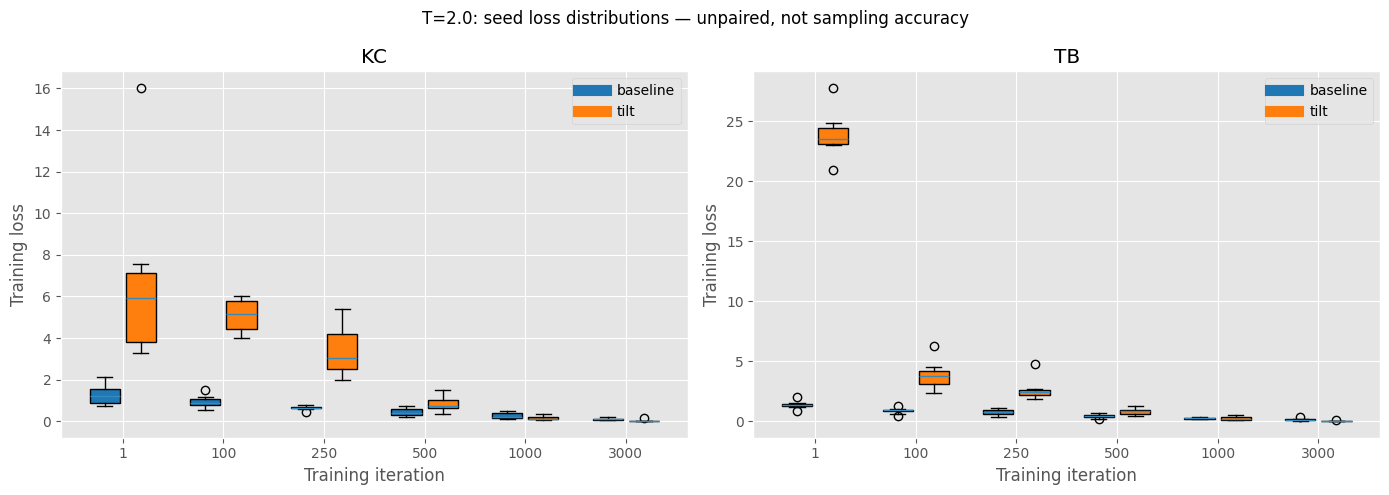

In [54]:
checkpoints = [t for t in [1, 100, 250, 500, 1000, 3000] if t in set(h.iteration)]; fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ["kc", "tb"]):
    for variant, offset, color in [("baseline", -.18, "tab:blue"), ("tilt", .18, "tab:orange")]:
        samples = [h[(h.method==method) & (h.variant==variant) & (h.iteration==t)].loss.dropna().to_numpy() for t in checkpoints]
        if any(len(a) for a in samples): boxes = ax.boxplot([a for a in samples if len(a)], positions=[i+offset for i,a in enumerate(samples) if len(a)], widths=.3, patch_artist=True, manage_ticks=False); [patch.set_facecolor(color) for patch in boxes["boxes"]]; ax.plot([], [], color=color, lw=8, label=variant)
    ax.set_xticks(range(len(checkpoints)), checkpoints); ax.set(title=method.upper(), xlabel="Training iteration", ylabel="Training loss"); ax.legend()
fig.suptitle("T=2.0: seed loss distributions — unpaired, not sampling accuracy"); fig.tight_layout(); plt.show()

# Early Stopping with Tilt

In [25]:
# This block labels my incoming tilt results, in the tilt_early folder.
folder = ROOT / "GFN_Thesis/outputs/tilt_early_20261111_225855"
with sqlite3.connect(SQL_DATABASE) as conn: 
    docs = conn.execute("SELECT path,content FROM archived_files WHERE path LIKE ?", (str(folder)+"/run_%.json",)).fetchall()
runs = [(p,j) for p,b in docs for j in [json.loads(b)] if j.get("status")=="completed"]

assert runs, "Import the early stopping data first"
with sqlite3.connect(SQL_DATABASE) as conn: 
    conn.execute("CREATE TABLE IF NOT EXISTS run_labels(source_path TEXT PRIMARY KEY, neural_variant TEXT, tilt_strength REAL)"); conn.executemany("INSERT OR REPLACE INTO run_labels VALUES(?,?,?)", [(p,j["config"]["variant"],j["config"]["tilt_strength"]) for p,j in runs])

probe = pd.DataFrame([{"source_path":p, **j["config"], **point} for p,j in runs for point in j["curve"]])
probe_stats = probe.groupby(["schedule","T","method","variant","it"]).kl_qp.agg(["mean","sem"]).reset_index()
print(f"Loaded {len(runs)} runs; {len(probe)} evaluations"); display(probe_stats.head())

Loaded 240 runs; 2400 evaluations


,schedule,T,method,variant,it,mean,sem
0,fixed,1.5,KC,baseline,0,6.498377,0.007055
1,fixed,1.5,KC,baseline,1,6.486040,0.006792
2,fixed,1.5,KC,baseline,5,6.429134,0.016404
3,fixed,1.5,KC,baseline,10,6.309694,0.037411
4,fixed,1.5,KC,baseline,25,4.183886,0.514411


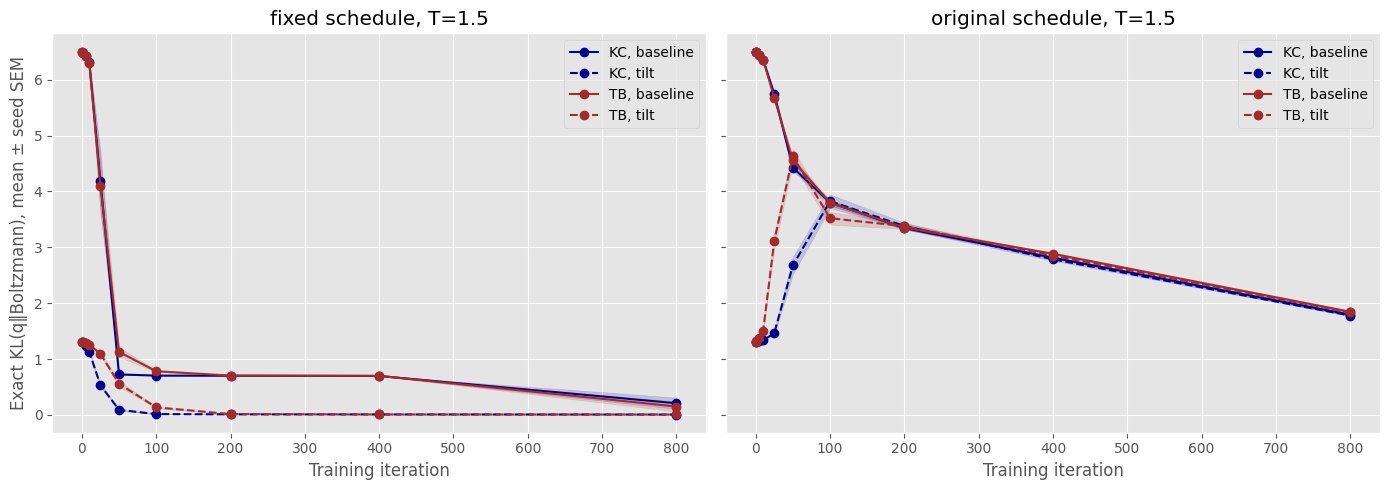

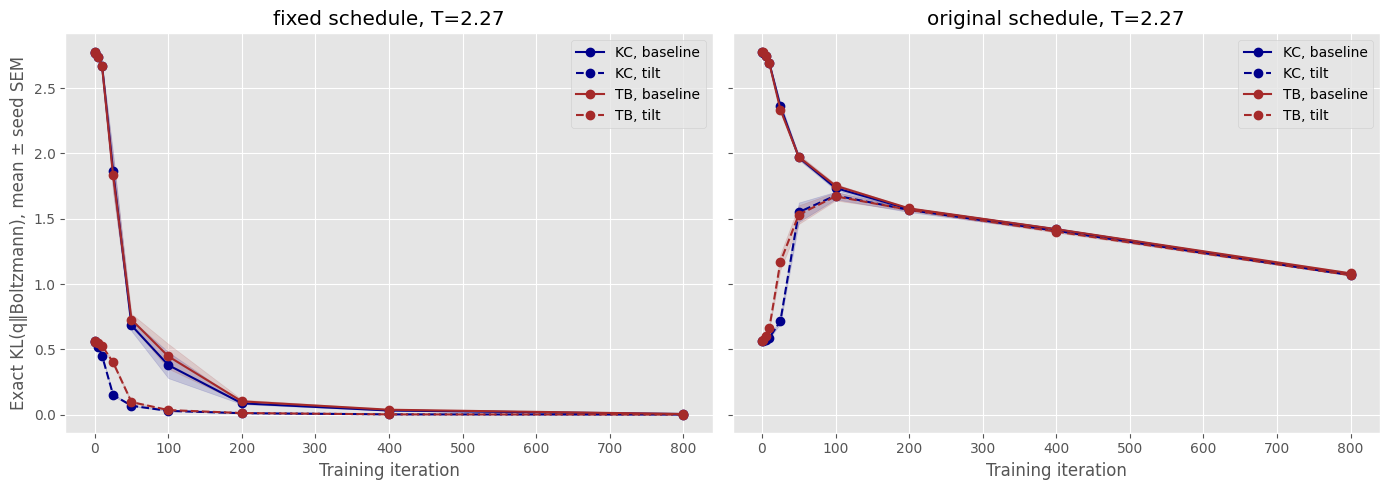

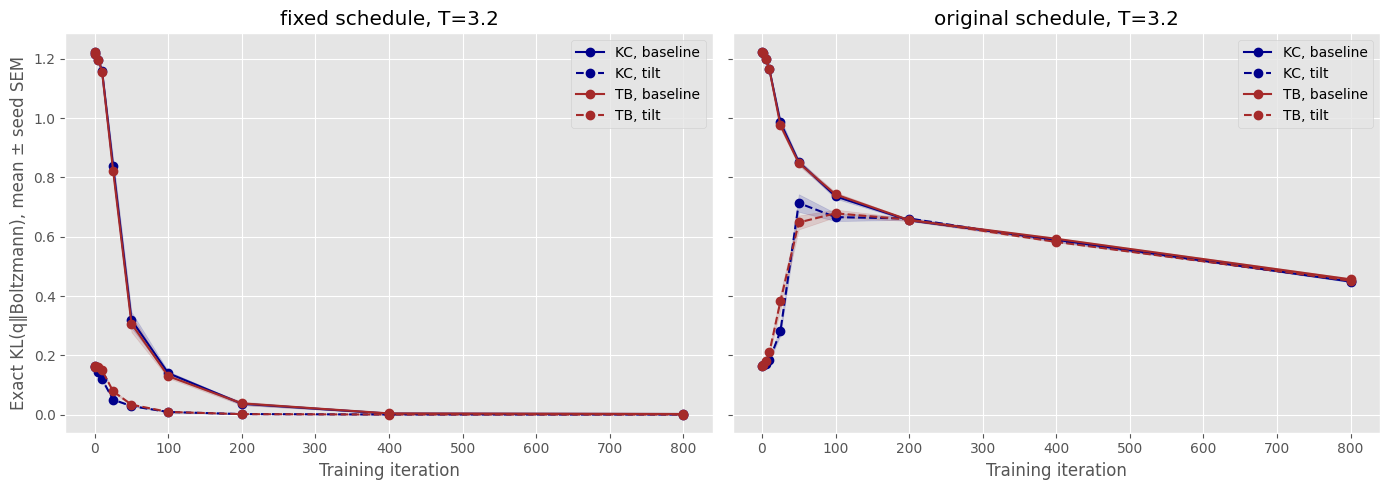

In [54]:
# Plot early stopping results for 
SAME_Y_SCALE=False
for T in [1.5, 2.27, 3.2]:
    colors={"baseline":{"KC":"darkblue","TB":"brown"},"tilt":{"KC":"darkblue","TB":"brown"}}
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for ax, schedule in zip(axes, ["fixed", "original"]):
        d = probe_stats[(probe_stats["T"] == T) & (probe_stats.schedule == schedule)]
        for (method, variant), g in d.groupby(["method", "variant"]):
            clr=colors[variant][method]
            g = g.sort_values("it"); line = ax.plot(g["it"], g["mean"], marker="o",color=clr, linestyle="--" if variant=="tilt" else "-", label=f"{method}, {variant}")[0]; ax.fill_between(g["it"], (g["mean"]-g["sem"].fillna(0)).clip(lower=0), g["mean"]+g["sem"].fillna(0), color=line.get_color(), alpha=.15)
        ax.set(xlabel="Training iteration", title=f"{schedule} schedule, T={T}")#, yscale="symlog")
        ax.legend()
        if SAME_Y_SCALE:
            ax.set(ylim=(-0.4,10))
    axes[0].set_ylabel("Exact KL(q‖Boltzmann), mean ± seed SEM"); fig.tight_layout(); plt.show()